In [1]:
from langchain_groq import ChatGroq
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from IPython.display import Image, display

In [ ]:
groq_api_key = ""
llm=ChatGroq(groq_api_key=groq_api_key, model_name="qwen/qwen3.8-27b")
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.8.4', 'langchain': '1.5.2', 'langchain-groq': '1.2.1'}}, profile={'name': 'Qwen3.8 27B', 'status': 'beta', 'release_date': '2026-08-14', 'last_updated': '2026-08-14', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 16384, 'text_inputs': True, 'image_inputs': True, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': True, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000001BB98C3DBE0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001BB98C3E660>, model_name='qwen/qwen3.8-27b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [3]:
class State(TypedDict):
    messages:Annotated[list, add_messages] 
    sentiment: str 
    
def preprocess(state: State) -> State:
    cleaned = state['messages'][-1].content.strip() 
    state['messages'][-1].content = cleaned 
    return state 

def analyze_sentiment(state: State) -> State:
    msg = state["messages"][-1].content
    state["sentiment"] = 'positive' if 'good' in msg else 'neutral'
    return state

def chatbot(state: State) -> State:
    return {'messages': llm.invoke(state['messages'])}

def logger(state: State) -> State:
    print(f'LOG:{state['messages'][-1].content}, Sentiment: {state.get('sentiment')}')
    return state    
    
    

In [4]:
builder = StateGraph(State)
builder.add_node('preprocess', preprocess)
builder.add_node('analyze_sentiment', analyze_sentiment)
builder.add_node('chatbot',chatbot)
builder.add_node('logger', logger)

In [5]:
builder.add_edge(START,'preprocess')
builder.add_edge('preprocess','analyze_sentiment')
builder.add_edge('analyze_sentiment', 'chatbot')
builder.add_edge('chatbot', 'logger')
builder.add_edge('logger', END)

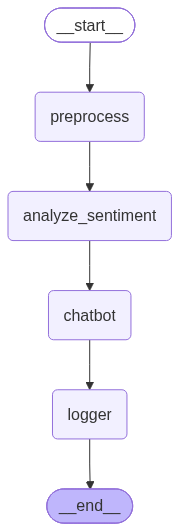

In [6]:
builder.compile()

In [7]:
graph = builder.compile()

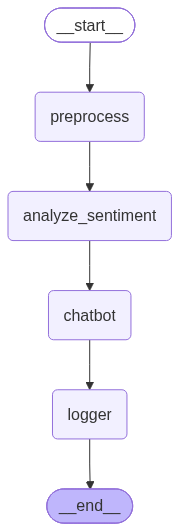

In [8]:
graph

In [9]:
input_message = 'tell me about  virat kholi'
final_state = graph.invoke({"messages":('user', input_message)})

print('Final state:', final_state)
print('chatbots responese:', final_state['messages'][-1].content)
print('Detected sentiment:', final_state['sentiment'])

input_message_2 = 'virat kholi date of birth'
final_state_2 = graph.invoke({"messages":('user', input_message_2)})

print('Final state 2:', final_state_2)
print('chatbots responese 2:', final_state_2['messages'][-1].content)
print('Detected sentiment 2:', final_state_2['sentiment'])

LOG:It appears there might be a slight confusion with the name. **Virat Kohli** is a famous Indian cricketer, not "Kholi." "Kholi" is often used in some regions (like parts of India) to refer to **kabaddi**, a traditional contact sport, but Virat Kohli is not associated with kabaddi.

Here are the key facts about **Virat Kohli**:

### 🏏 Who is Virat Kohli?
- **Full Name**: Virat Bhogi Kohli
- **Born**: November 5, 1988, in Delhi, India
- **Role**: Right-handed batsman and occasional all-rounder
- **Teams**:
  - **International**: India (Test, ODI, T20I)
  - **IPL**: Royal Challengers Bengaluru (formerly Kings XI Punjab for 2018)
  - **Domestic**: Delhi

### 🔥 Key Achievements:
1. **Highest ODI Run-Score in History**:
   - Holds the record for the most runs in One Day Internationals (ODIs) with over **13,000 runs**.
   - Most centuries in ODIs (49+).
2. **Test Cricket**:
   - One of the most consistent batsmen in Test cricket.
   - Holds records for most consecutive centuries, fastest t